In [12]:
import at
import numpy as np
import scipy
import matplotlib.pyplot as plt
import pickle
import os

from copy import deepcopy

In [4]:
with open('candidates/v01_01_01_01/ring.pkl', 'rb') as file:
    ring0 = pickle.load(file)

In [5]:
N = len(ring0)
s_pos = ring0.get_s_pos()

In [6]:
UC_index = ring0.uint32_refpts('UCborder')

print("Matching section:")
print([e.FamName for e in ring0[:UC_index[0] + 1]])

print("Unit cell:")
print([e.FamName for e in ring0[UC_index[0] : UC_index[1]+1]])

Matching section:
['str0500', 'str0500', 'str0500', 'str0500', 'str0321', 'GS', 'bpm_d', 'BPM', 'bpm_d', 'str0010', 'corrh_ac', 'corrv_ac', 'str0048', 'corr_d', 'corrv', 'corr_d', 'corr_d', 'corrh', 'corr_d', 'str0021', 'O1_v1', 'O1_v1', 'str0025', 'Q1_v1', 'str0025', 'O2_v1', 'O2_v1', 'str0100', 'Q2_v1', 'strx006', 'D1_v1', 'D1_v1', 'D1_v1', 'D1_v1', 'D1_v1', 'D1_v1', 'D1_v1', 'D1_v1', 'D1_v1', 'D1_v1', 'D1_v1', 'D1_v1', 'O3_v1', 'corrv', 'O3_v1', 'strx092', 'corr_d', 'corr_d', 'corr_d', 'corrh', 'corr_d', 'bpm_d', 'BPM', 'bpm_d', 'str0020', 'S1_v1', 'LSborder', 'S1_v1', 'GE', 'str2', 'GS', 'Q3_v1', 'str1', 'S2_v1', 'UCborder']
Unit cell:
['UCborder', 'S2_v1', 'strx013', 'bpm_d', 'BPM', 'bpm_d', 'strx013', 'R1_v1', 'str0100', 'corr_d', 'corrv', 'corr_d', 'corr_d', 'corrh', 'corr_d', 'strx203', 'S3_v1', 'S3_v1', 'str0010', 'str3', 'D2_v1', 'D2_v1', 'D2_v1', 'D2_v1', 'D2_v1', 'D2_v1', 'D2_v1', 'D2_v1', 'D2_v1', 'D2_v1', 'D2_v1', 'D2_v1', 'D2_v1', 'D2_v1', 'D2_v1', 'D2_v1', 'str3', 'str0

## Optics matching

In [7]:
ring = deepcopy(ring0)

In [8]:
# Correct beta beating and dispersion
# elemdata_UC = at.linopt4(ring[UC_index[0]:UC_index[1]+1], at.All)[0] # Optics functions required for matching

# For scaling D1 strengths
D1_refpts = ring0.uint32_refpts('D1_v1')
D1_K0 = np.array([ring0[i].K for i in D1_refpts])

goal_tune = np.array([58.3202, 18.1676]) # TDR-1

def set_D1_scale(value):
    for i, K0 in zip(D1_refpts, D1_K0):
        ring[i].K = value* K0

def get_D1_scale(**kwargs):
    return ring[D1_refpts[0]].K / D1_K0[0]

vars = at.VariableList([
    at.CustomVariable(set_D1_scale, get_D1_scale, name='D1 scale', delta=1e-3),
    at.RefptsVariable('R1_v1', attrname='K', name='R1', delta=1e-5),
    at.RefptsVariable('Q1_v1', attrname='K', name='Q1', delta=1e-5),
    at.RefptsVariable('Q2_v1', attrname='K', name='Q2', delta=1e-5),
    at.RefptsVariable('Q3_v1', attrname='K', name='Q2', delta=1e-5),
])

obs = at.ObservableList([
    at.LocalOpticsObservable(UC_index, 'alpha', plane='x', target=0, weight=1/len(UC_index)),
    at.LocalOpticsObservable(UC_index, 'alpha', plane='y', target=0, weight=1/len(UC_index)),
    at.LocalOpticsObservable(at.End, 'mu', plane='x', target=2*np.pi*goal_tune[0]/20),
    at.LocalOpticsObservable(at.End, 'mu', plane='y', target=2*np.pi*goal_tune[1]/20),
    at.LocalOpticsObservable(0, 'dispersion', plane=0, target=0),
    at.LocalOpticsObservable(0, 'dispersion', plane=1, target=0),
])

ring.match(vars, obs, verbose=2)


16 constraints, 5 variables, using method lm

`xtol` termination condition is satisfied.
Function evaluations 14, initial cost 1.6568e-02, final cost 2.8778e-20, first-order optimality 2.00e-12.

Constraints:

    location              Initial            Actual         Low bound        High bound         deviation 
alpha[x]
    UCborder         -2.02018e-10       5.53892e-09               0.0               0.0       5.53892e-09 
    UCborder         -1.64114e-08      -6.64184e-08               0.0               0.0      -6.64184e-08 
    UCborder           -1.008e-08      -4.26171e-08               0.0               0.0      -4.26171e-08 
    UCborder          1.00955e-08       4.26312e-08               0.0               0.0       4.26312e-08 
    UCborder          1.64127e-08        6.6423e-08               0.0               0.0        6.6423e-08 
    UCborder          1.80212e-10      -5.56174e-09               0.0               0.0      -5.56174e-09 
alpha[y]
    UCborder         -

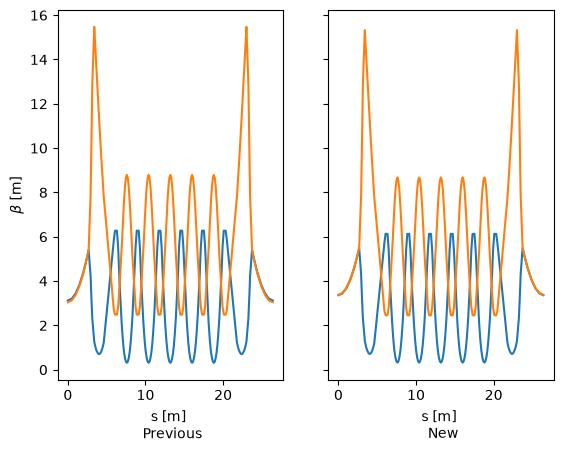

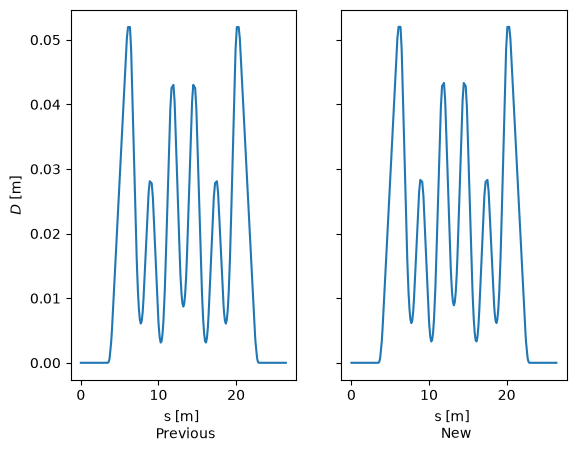

In [9]:
elemdata0 = ring0.linopt4(at.All)[2]
elemdata = ring.linopt4(at.All)[2]

fig, axs = plt.subplots(1, 2, sharey=True)
axs[0].plot(elemdata0.s_pos, elemdata0.beta)
axs[1].plot(elemdata.s_pos, elemdata.beta)
axs[0].set_xlabel('s [m] \n Previous')
axs[1].set_xlabel('s [m] \n New')
axs[0].set_ylabel('$\\beta$ [m]')
plt.show()

fig, axs = plt.subplots(1, 2, sharey=True)
axs[0].plot(elemdata0.s_pos, elemdata0.dispersion[:, 0])
axs[1].plot(elemdata.s_pos, elemdata.dispersion[:, 0])
axs[0].set_xlabel('s [m] \n Previous')
axs[1].set_xlabel('s [m] \n New')
axs[0].set_ylabel('$D$ [m]')
plt.show()

In [10]:
# Correct chromaticity
xi_goal = [2, 2]
at.fit_chrom(ring, 'S3_v1', 'S4_v1', xi_goal) 


Fitting Chromaticity...
Initial value [2.3337835  3.20964446]
iter# 0 Res. 4.565670837544563e-07
iter# 1 Res. 1.467162589856252e-14
Final value [2.0000001  2.00000007] 



Tunes: [58.87 18.35] -> [58.32 18.17]
Chromaticity: [2.07 1.93] -> [2. 2.]


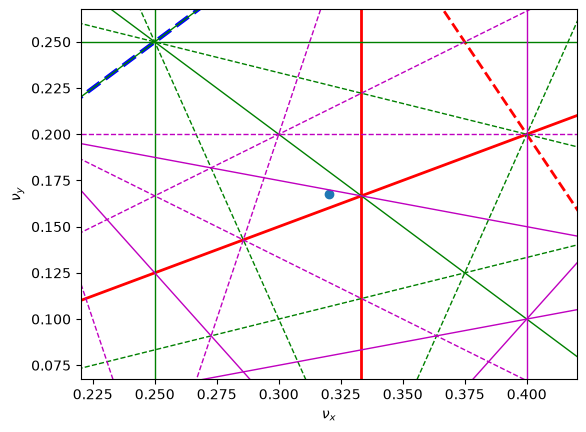

In [11]:
print(f'Tunes: {ring0.get_tune(get_integer=True).round(2)} -> {ring.get_tune(get_integer=True).round(2)}')
print(f'Chromaticity: {ring0.get_chrom().round(2)} -> {ring.get_chrom().round(2)}')

tunes = ring.get_tune()
at.plot.resonances.plot_tune_diagram(orders=[1, 2, 3, 4, 5], show=False)
plt.scatter(*tunes)
plt.xlim(tunes[0]-0.1, tunes[0]+0.1)
plt.ylim(tunes[1]-0.1, tunes[1]+0.1)
plt.show()

## Save lattice

In [ ]:
lattice_name = 'v01_01_03_01'
date = '260925'

try:
    os.mkdir(f'candidates/{lattice_name}')
except FileExistsError:
    pass
    
with open(f'candidates/{lattice_name}/ring.pkl', 'wb') as file:
    pickle.dump(ring, file)

at.save_mat(ring, f'candidates/{lattice_name}/achro.mat')